

---------------- Top 10 hospitals based on Survey Response Rate ----------------------


1. Merge Hospital Name with the hospital_survey table


2. Check DataType for Survey Response Rate Percent


Data Type: object


3. Change value to number


4. Datatype is updated to num


Data Type: float64


5. Groupby Hospital_id, Hospital name and get the mean for Survey Response Rate Percent


# Top 10 hospitals based on Survey Response Rate


     Hospital_ID                           Hospital Name  Survey Response Rate Percent
645        60117           ANIMAS SURGICAL HOSPITAL, LLC                          60.0
153        30107        ARIZONA SPINE AND JOINT HOSPITAL                          57.0
514        50708                FRESNO SURGICAL HOSPITAL                          55.0
521        50726            STANISLAUS SURGICAL HOSPITAL                          54.0
547        50769               HOAG ORTHOPEDIC INSTITUTE                          54.0
154        30108  CORE INSTITUTE SPE

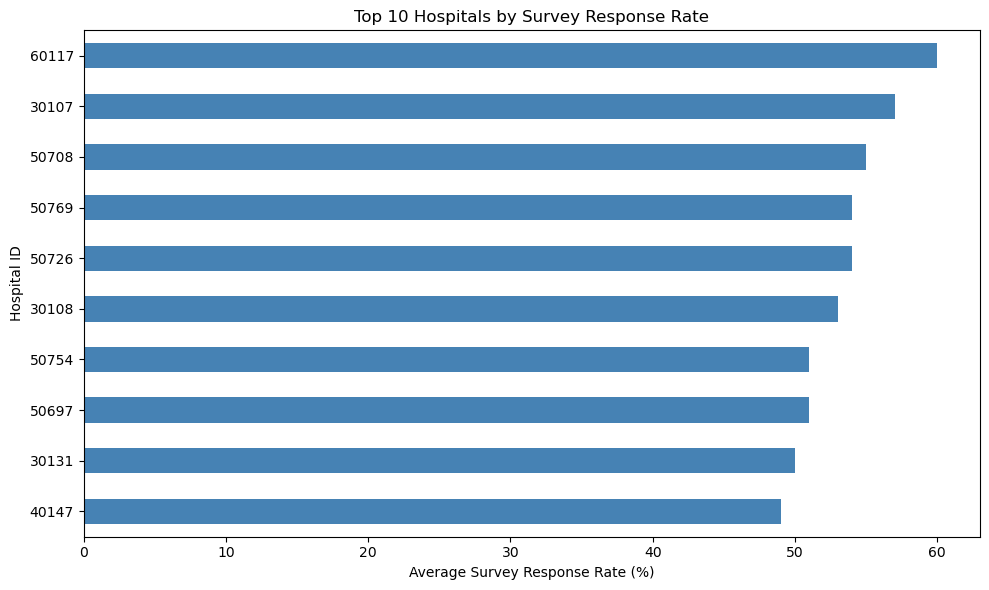

In [261]:
import pandas as pd

df = pd.read_csv('Health Care_Patient_survey_source.csv')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.max_colwidth', None)

# print(df.head())

# print(df.columns.to_list())


# display(
# df[['Provider ID', 'Hospital Name', 'State', 'City']]
    
# )

# Creat hospital_dim
# Select Provider ID, Hospital Name, State, City, ZIP Code, and Location.
# Use .drop_duplicates() on those selected columns to keep distinct hospital records.
# Use .reset_index(drop=True) to give the new table a clean index.

hospital_dim = df[['Provider ID', 'Hospital Name', 'State', 'City', 'ZIP Code', 'Location']].drop_duplicates().reset_index(drop=True)

# Check if provider ID is unique

# display(hospital_dim['Provider ID'].is_unique)
# display(hospital_dim['Provider ID'].isna().sum())


# Rename Provider ID to to Hospital_ID to match  schema. Try using .rename(columns={...}) and assign the result back to hospital_dim.

hospital_dim = hospital_dim.rename(columns={'Provider ID': 'Hospital_ID'})



# Check Zip Code column value length, looks like some are < 5 (standard US zip length)

# display(
#     hospital_dim.loc[
#         hospital_dim['ZIP Code'].astype('string').str.len() < 5
#     ]
# )


hospital_dim['ZIP Code'] = hospital_dim['ZIP Code'].astype('string')

hospital_dim['ZIP Code'] = hospital_dim['ZIP Code'].str.zfill(5)

# print(hospital_dim.tail())

# display(
#     hospital_dim.loc[
#         hospital_dim['ZIP Code'].astype('string').str.len() < 5
#     ]
# )


# Create a DataFrame location_dim 
# - County Name
# - State
# - City
# - ZIP Code

location_dim  = df[['County Name', 'State', 'City', 'ZIP Code']].drop_duplicates().reset_index(drop=True)

# display(location_dim.loc[
#     location_dim['ZIP Code'].astype('string').str.len() < 5
#     ]
# )

# Changes the  datatype from number to string
location_dim['ZIP Code'] = location_dim['ZIP Code'].astype('string')

# Fills in with a 0 
location_dim['ZIP Code'] = location_dim['ZIP Code'].str.zfill(5)




# display(location_dim.loc[
#     location_dim['ZIP Code'].astype('string').str.len() == 5
#     ]
# )


# CREATE COUNTY_ID COLUMN AS PK
location_dim['County_ID'] = location_dim.index + 1

# print(location_dim.head())



# display(
#     location_dim[
#         location_dim.duplicated(
#             subset= ['State', 'City', 'ZIP Code'],
#             keep=False
#         )
#     ]
    
# )


# print(hospital_dim.head())
# print(location_dim.head())
# Bring County ID into the hospital_dim table

hospital_dim = hospital_dim.merge(
    location_dim[['County_ID','State', 'City', 'ZIP Code']],
    on=['State', 'City', 'ZIP Code'],
    how='left',
    validate='many_to_one'
    
)

# display(hospital_dim.head())

# Count rows of hospital_dim

# print(len(location_dim))

# print(hospital_dim['County_ID'].isna().sum())


# survey_dim  table:
# - Question
# - Answer Description
# - Patient Survey Star Rating Footnote


# print(df.columns.to_list())
survey_dim = df[['Question', 'Answer Description','Patient Survey Star Rating Footnote']].drop_duplicates().reset_index(drop=True)

survey_dim['Survey_Id'] = survey_dim.index + 1

# display(survey_dim.isna().sum())

# print(survey_dim.head())



measure_dim = df[['Measure ID', 'Measure Start Date', 'Measure End Date']].drop_duplicates().reset_index(drop=True)
# display(measure_dim.isna().sum())
measure_dim['measure_id'] = measure_dim.index + 1


# print(measure_dim)

# print(hospital_dim.columns.to_list())
# print(location_dim.columns.to_list())
# print(measure_dim.columns.to_list())
# print(survey_dim.columns.to_list())
# print(df.columns.to_list())


fact_table = df[['Number of Completed Surveys', 
                 'Number of Completed Surveys Footnote', 
                 'Survey Response Rate Percent', 
                 'Survey Response Rate Percent Footnote', 
                 'Linear Mean Value',
                 'Answer Percent',
                 'Patient Survey Star Rating',
                 'Provider ID',
                 'Measure ID',
                 'Question', 
                 'Answer Description',
                 'Patient Survey Star Rating Footnote'
                
                ]].reset_index(drop=True).rename(columns={'Provider ID': 'Hospital_ID'})

# print(fact_table.head())

# print(fact_table.isna().sum())


# print(fact_table.head())

fact_table = fact_table.merge(
    hospital_dim[['County_ID', 'Hospital_ID']],
    on='Hospital_ID',
    how='left',
    validate='many_to_one'
)



# print(fact_table.columns.to_list())

# print(len(df), len(fact_table))
# print(fact_table['County_ID'].isna().sum())

fact_table = fact_table.merge(
    measure_dim[['Measure ID', 'measure_id']],
    on='Measure ID',
    how='left',
    validate="many_to_one"
)



fact_table = fact_table.merge(
    survey_dim[
        ['Survey_Id',
         'Question', 
         'Answer Description',
         'Patient Survey Star Rating Footnote'
        ]
    ],
    on=[
        'Question', 
         'Answer Description',
         'Patient Survey Star Rating Footnote'
    ],
    how='left',
    validate="many_to_one"
)



# display(fact_table.columns.to_list)

# print(len(df), len(fact_table))
# print(fact_table.isna().sum())


# display(fact_table.head())
# display(fact_table[fact_table['Hospital_ID'] == 10001])

# display(measure_dim[
#     ['Measure Start Date', 'Measure End Date']
#     ].drop_duplicates()
#        )

# display(fact_table.head())
# print(fact_table.columns.to_list())
# display(fact_table.isna().sum())
# make a separate report table containing just the hospital and survey count:

# AFTER MERGEING , KEEPING ONLY THE COLUMNS THAT ARE PART OF THE SCHEMA DESIGN

fact_table = fact_table[
    [
        'Hospital_ID',
        'County_ID',
        'measure_id',
        'Survey_Id',
        'Number of Completed Surveys',
        'Number of Completed Surveys Footnote',
        'Survey Response Rate Percent',
        'Survey Response Rate Percent Footnote',
        'Linear Mean Value',
        'Answer Percent',
        'Patient Survey Star Rating'
    ]
].copy()

# display(fact_table.columns.to_list)


# Number of surveys  Completed by different Hospitals

completed_surveys = fact_table[
    ['Hospital_ID', 'Number of Completed Surveys']
].drop_duplicates()

# print(completed_surveys)

# Top 3 Counties which have the highest survey rate.


# create counties_survey
# Select columns ['Hospital_ID', 'County_ID', 'Survey Response Rate Percent']
# drop_duplicated()
# make a copy
# Using pd.to_numeric(
#     change Survey Response Rate Percent to numeric
#     erros = 'coerce'
# )


counties_survey = (fact_table
        [['Hospital_ID', 'County_ID', 'Survey Response Rate Percent']]
        .drop_duplicates()
        .copy()
                )
counties_survey['Survey Response Rate Percent'] = pd.to_numeric(
    counties_survey['Survey Response Rate Percent'],
    errors = 'coerce'
)


# print(counties_survey['Survey Response Rate Percent'].dtype)


# Merge the County_name and State to the County_survey table, we need this because our location table can have several IDs for the same county

counties_survey = counties_survey.merge(
      location_dim[['County_ID','County Name', 'State']],
        on='County_ID',
        how='left',
        validate='many_to_one'
    
)



top_3_counties = (
    counties_survey
    .groupby(['County Name', 'State'])['Survey Response Rate Percent']
    .mean()
    .reset_index()
    .sort_values(by='Survey Response Rate Percent', ascending=False)
    .head(3)
    
)


# print('# Top 3 Counties which have the highest survey rate.\n')
# print('\n')
# print(top_3_counties)


print('\n')
print('---------------- Top 10 hospitals based on Survey Response Rate ----------------------')
print('\n')

# hospital_id, hospital_name, Survey Response Rate

hospital_survey = fact_table[['Hospital_ID','Survey Response Rate Percent']]

print('1. Merge Hospital Name with the hospital_survey table')
print('\n')

hospital_survey = hospital_survey.merge(
    hospital_dim[['Hospital_ID', 'Hospital Name']],
    on='Hospital_ID',
    how='left',
    validate='many_to_one'
)


print('2. Check DataType for Survey Response Rate Percent')
print('\n')

print('Data Type:',hospital_survey['Survey Response Rate Percent'].dtype)
print('\n')
print('3. Change value to number')
print('\n')

hospital_survey['Survey Response Rate Percent']= pd.to_numeric(
       hospital_survey['Survey Response Rate Percent'],
        errors='coerce'
)

print('4. Datatype is updated to num')
print('\n')
print('Data Type:',hospital_survey['Survey Response Rate Percent'].dtype)
print('\n')
print('5. Groupby Hospital_id, Hospital name and get the mean for Survey Response Rate Percent')
print('\n')


      
top_10_hospitals = (hospital_survey
                    .groupby(['Hospital_ID', 'Hospital Name'])['Survey Response Rate Percent']
                    .mean()
                    .reset_index()
                    .sort_values(by='Survey Response Rate Percent', ascending=False)
                    .head(10)
    
)

print('# Top 10 hospitals based on Survey Response Rate')
print('\n')
print(top_10_hospitals)




print('\n')
print('---------------- List the hospitals which are in same city ----------------------')
print('\n')

# We need hospital_ID, hospital_name, city, state

# print(hospital_dim.columns.to_list())
# print(location_dim.columns.to_list())
# print(measure_dim.columns.to_list())
# print(survey_dim.columns.to_list())
# print(fact_table.columns.to_list()



hospital_dim = (hospital_dim[
    (hospital_dim['City'] == hospital_dim['City'] ) &
    (hospital_dim['State'] == hospital_dim['State'] ) 
     ]
               )

# print(hospital_dim['Hospital Name'].is_unique)
# print(hospital_dim['Hospital Name'].duplicated())


same_city = hospital_dim[
    hospital_dim.duplicated(subset=['City', 'State'], keep=False)
]

print(same_city)


print('\n')
print('1. Total Survey Response rate by all the Hospitals.')
print('\n')


# print(hospital_dim.columns.to_list())
# print(location_dim.columns.to_list())
# print(measure_dim.columns.to_list())
# print(survey_dim.columns.to_list())
# print(fact_table.columns.to_list())

total_response_rate = (fact_table.groupby('Hospital_ID')['Survey Response Rate Percent'].sum()
    
)
print(total_response_rate)



import matplotlib.pyplot as plt

# Convert the response rate to numeric; invalid values become NaN
fact_table["Survey Response Rate Percent"] = pd.to_numeric(
    fact_table["Survey Response Rate Percent"],
    errors="coerce"
)

# Calculate the average response rate for each hospital
hospital_rates = (
    fact_table
    .groupby("Hospital_ID")["Survey Response Rate Percent"]
    .mean()
    .nlargest(10)
    .sort_values()
)

# Create the chart
hospital_rates.plot(kind="barh", figsize=(10, 6), color="steelblue")

plt.title("Top 10 Hospitals by Survey Response Rate")
plt.xlabel("Average Survey Response Rate (%)")
plt.ylabel("Hospital ID")
plt.tight_layout()
plt.show()


     Hospital_ID                     Hospital Name State              City ZIP Code                                                                   Location  County_ID
0          10001  SOUTHEAST ALABAMA MEDICAL CENTER    AL            DOTHAN    36301            1108 ROSS CLARK CIRCLE DOTHAN, AL 36301 (31.214058, -85.361725)          1
5          10011                 ST VINCENT'S EAST    AL        BIRMINGHAM    35235    50 MEDICAL PARK EAST DRIVE BIRMINGHAM, AL 35235 (33.595351, -86.665182)          6
8          10018             CALLAHAN EYE HOSPITAL    AL        BIRMINGHAM    35233          1720 UNIVERSITY BLVD BIRMINGHAM, AL 35233 (33.503137, -86.802401)          9
12         10023      BAPTIST MEDICAL CENTER SOUTH    AL        MONTGOMERY    36116     2105 EAST SOUTH BOULEVARD MONTGOMERY, AL 36116 (32.327144, -86.276764)         13
13         10024     JACKSON HOSPITAL & CLINIC INC    AL        MONTGOMERY    36106              1725 PINE STREET MONTGOMERY, AL 36106 (32.366606, -86